# 2.1. Separating signals from noise

In [2]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

%matplotlib inline

# Helper function

In [3]:
# xmr process statistics calculations
def xmr_process_stats(data):
    
    # Calculate mean
    mean = data.mean()
    
    # Calculate the moving range
    mRs = data.diff().abs()
    ave_mR = mRs.mean()

    # Calculate process limits
    UPL = mean + (2.660 * ave_mR)
    LPL = mean - (2.660 * ave_mR)
    URL = 3.268 * ave_mR
    
    return {
        'Mean': mean,
        'Ave. mR': ave_mR,
        'UPL': UPL,
        'LPL': LPL,
        'URL': URL
    }

In [4]:
# Get data 
url = r'https://raw.githubusercontent.com/jimlehner/crash-course-in-variation/refs/heads/main/data/additional_resistance_measurements.csv'
# Get data function
def get_data(dataset_url) -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get the data
df = get_data(url)

df['Sample No.'] = df['Sample No.'].astype('string')

df.head()

,Stage,Units,Sample No.,Resistance
0,Additional,megohms,1,4400
1,Additional,megohms,2,4565
2,Additional,megohms,3,4495
3,Additional,megohms,4,4325
4,Additional,megohms,5,4385


# Calculate process statistics

In [7]:
stats = xmr_process_stats(df['Resistance'])

mean = stats['Mean'].round(2)
UPL = stats['UPL'].round(2)
LPL = max(0, stats['LPL'].round(2))
ave_mR = stats['Ave. mR'].round(2)
URL = stats['URL'].round(2)

# Create labeled time series

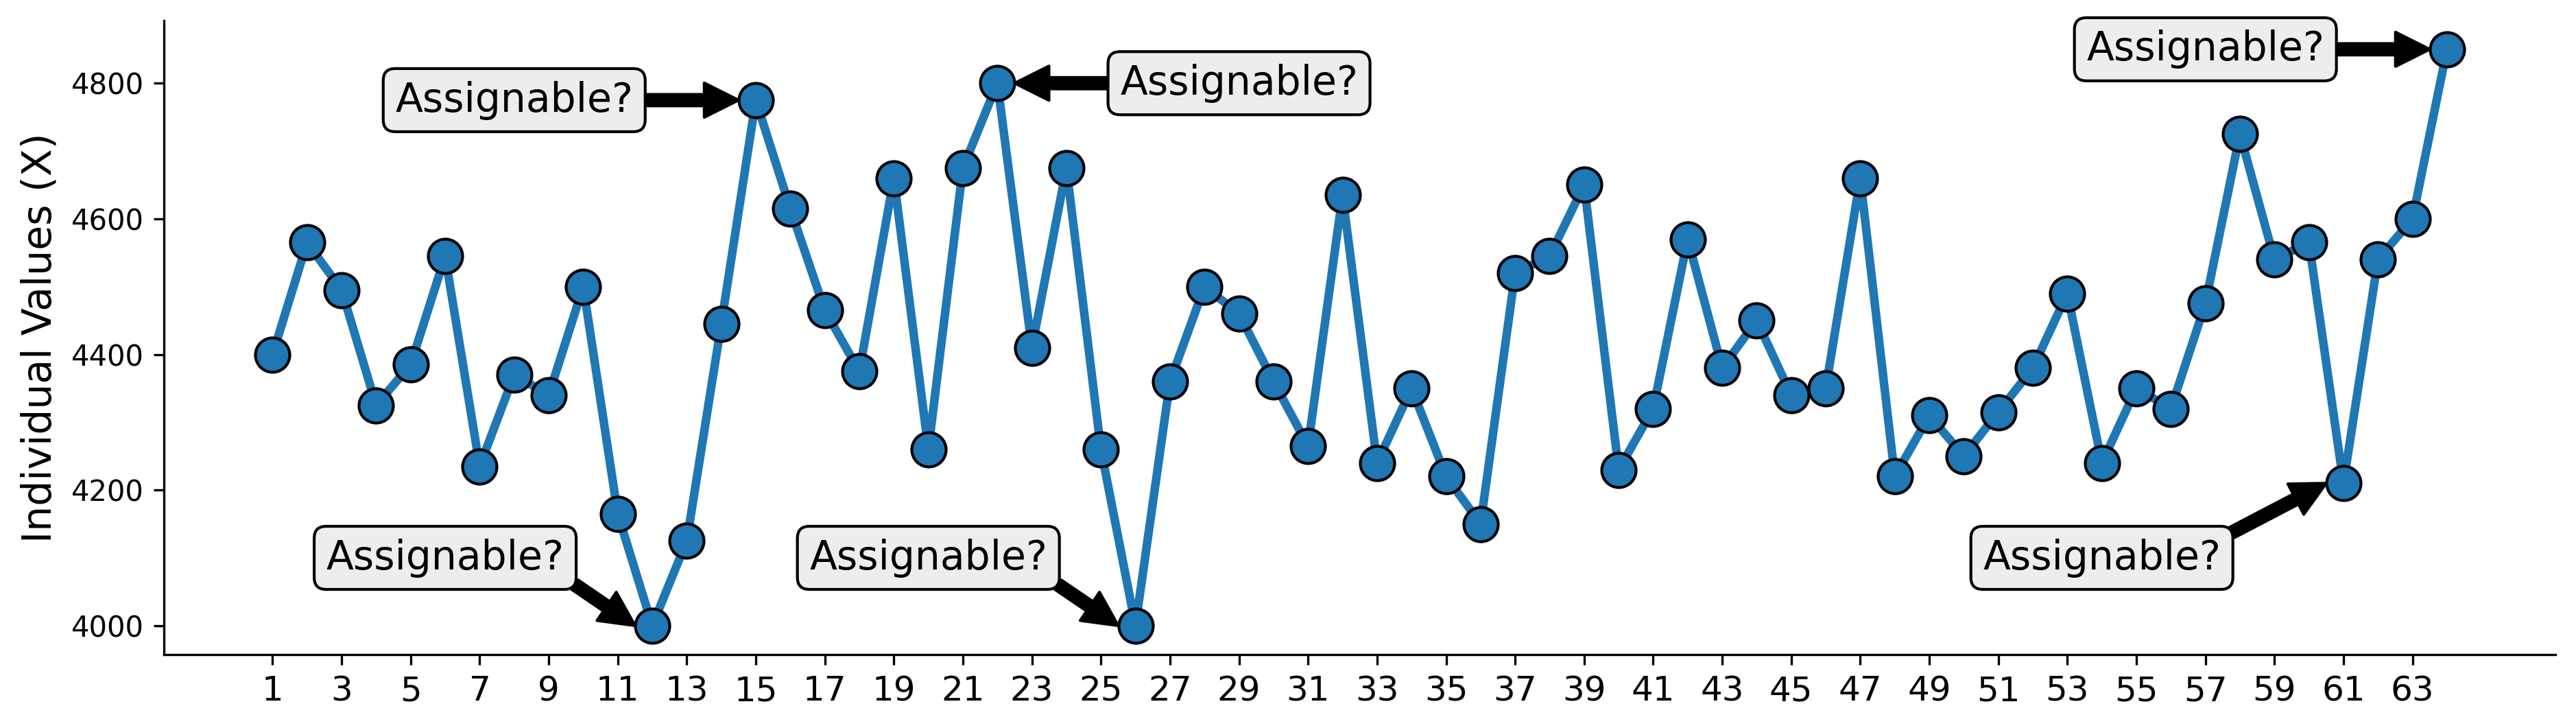

In [35]:
data = df['Resistance']
labels = df['Sample No.']

# Create matplotlib figure
fig, axs = plt.subplots(
                       figsize=(15,4),
                       dpi=300)

# Time series
axs.plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(0, len(labels), 2)
axs.set_xticks(tick_positions)
axs.set_xticklabels(
    labels[::2],
    ha='center', 
    fontsize=12
)

annotations = {
    (10.5, 4000, 5, 4100),
    (13.5, 4775, 7, 4775),
    (24.5, 4000, 19, 4100),
    (21.5, 4800, 28, 4800),
    (59.5, 4210, 53, 4100),
    (62.5, 4850, 56, 4850),
}

for x, y, xtext, ytext in annotations:
    axs.annotate(
        'Assignable?',
        xy=(x, y),
        xytext=(xtext, ytext),
        ha='center',
        va='center',
        fontsize=14,
        bbox=dict(
            facecolor='#EDEDED',
            boxstyle='round',
            edgecolor='black'
        ),
        arrowprops=dict(
            color='black'
        ),
        zorder=5
    )

axs.set_ylabel('Individual Values (X)', fontsize=14)

# Despine
sns.despine()
    
plt.show()

# Create XmR chart

In [37]:
# Specify x chart line parameters
xchart_lines = [
    (mean, "-", "black"),
    (UPL, "--", "#d72323"),
    (LPL, "--", "#d72323")
]

# Specify mR chart parameters
mrchart_lines = [
    (ave_mR, "-", "black"),
    (URL, "--", "#d72323"),
]

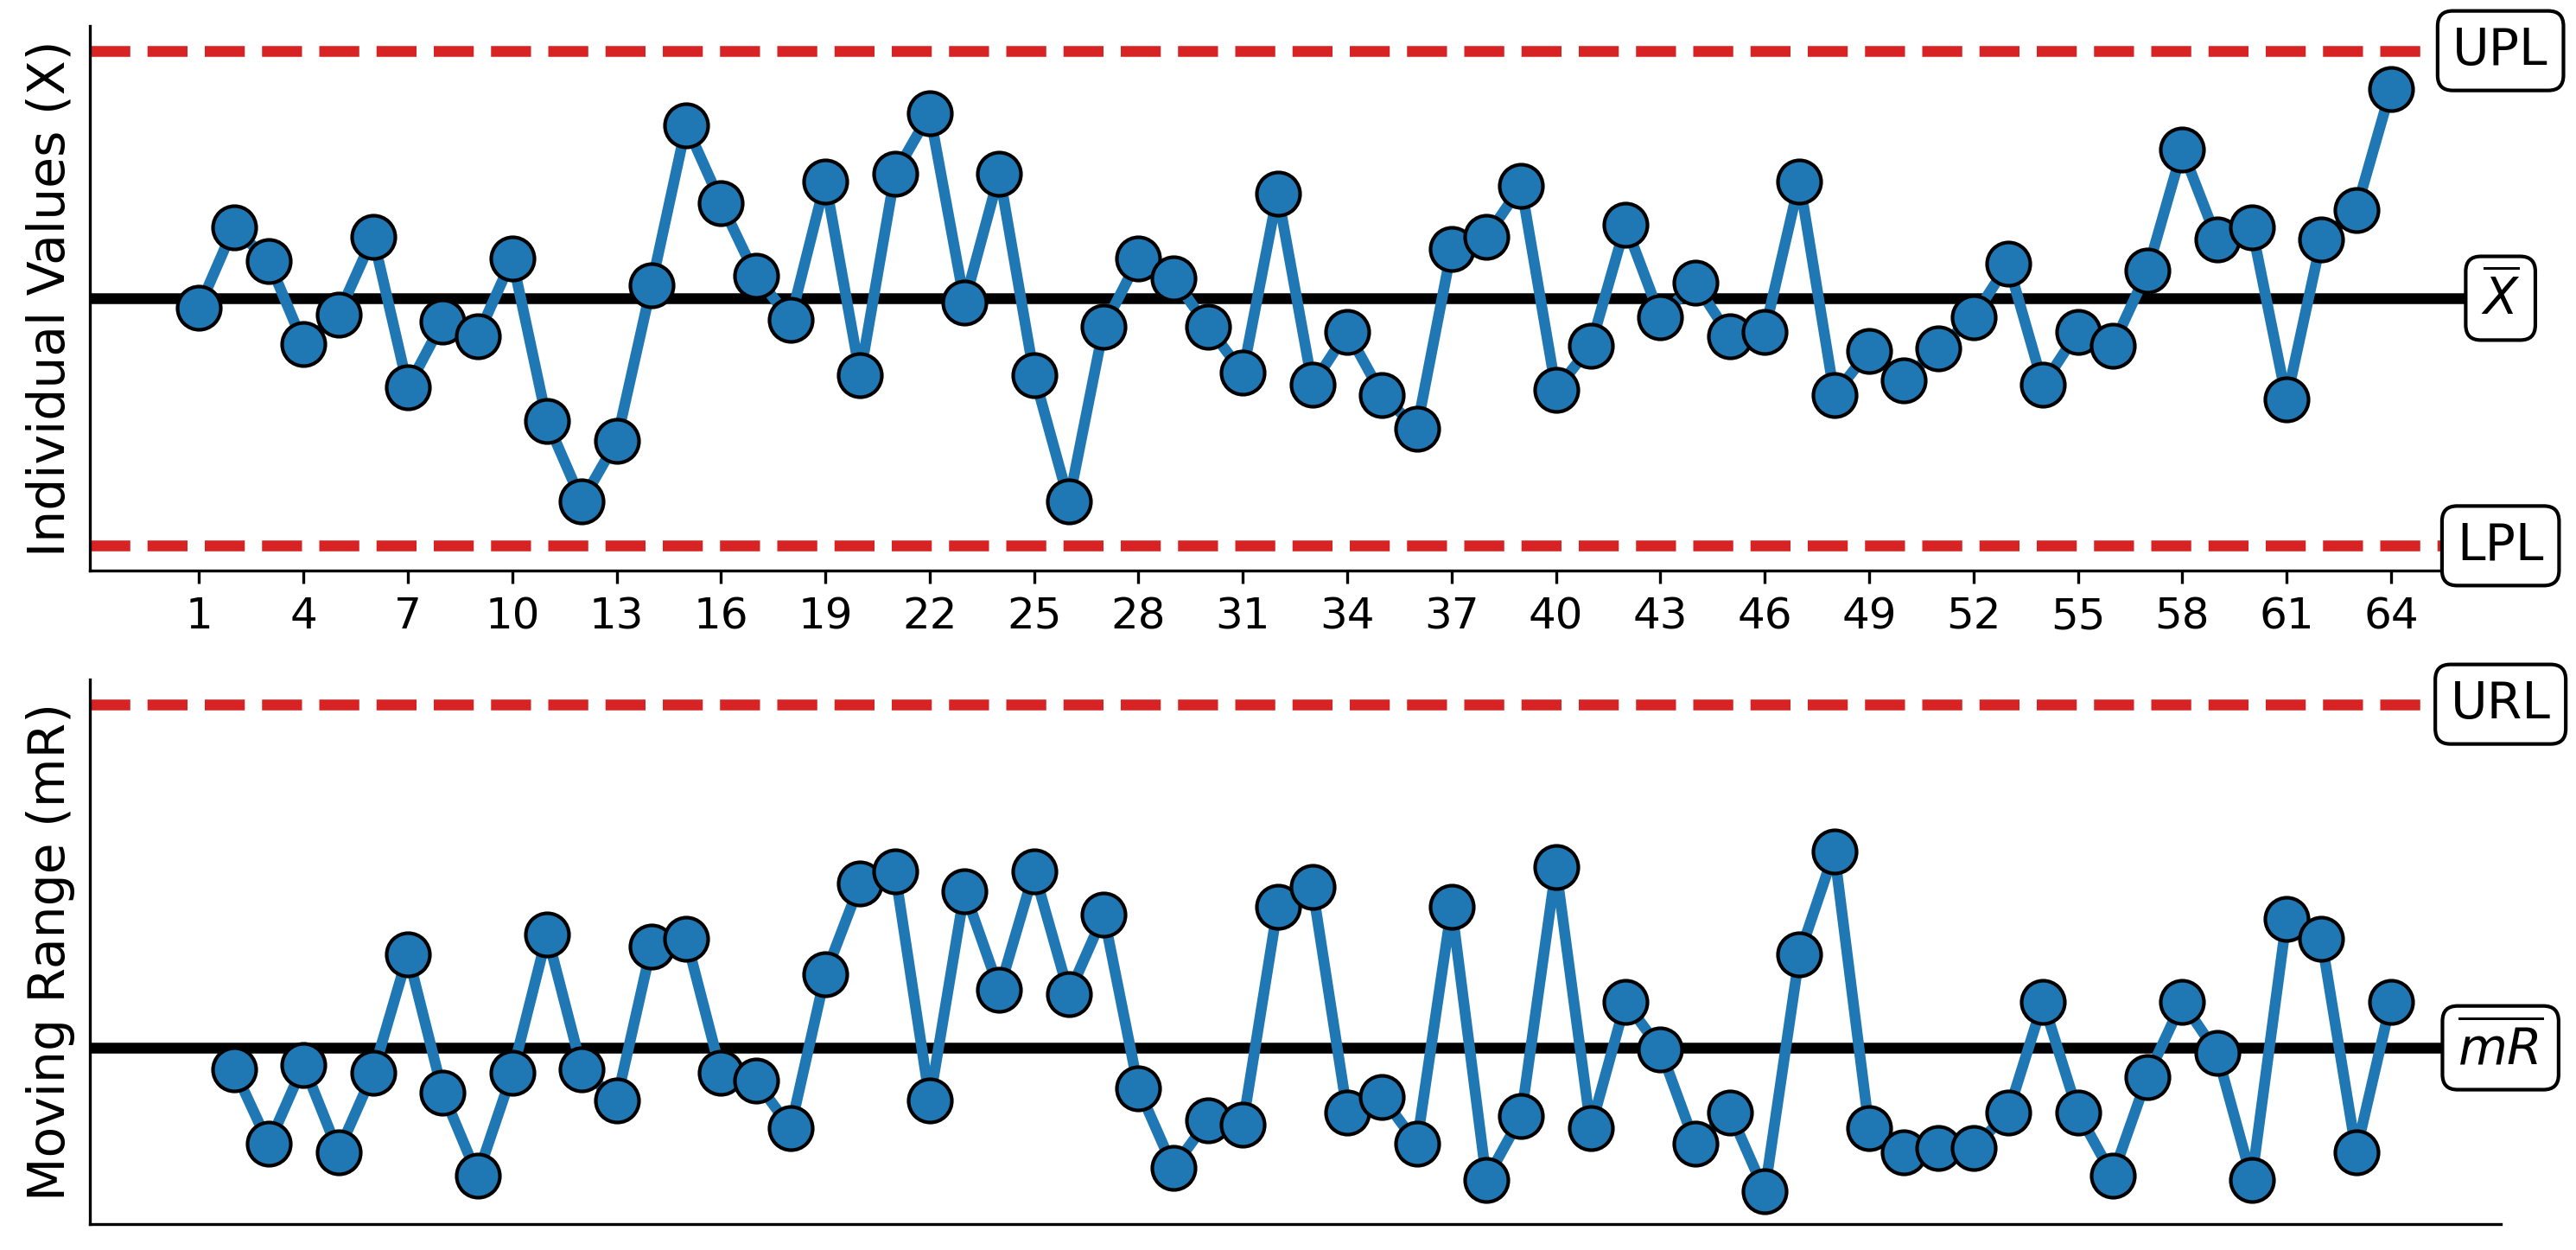

In [39]:
data = df['Resistance']
mRs = abs(data.diff())
labels = df['Sample No.']

# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# X chart
axs[0].plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(0, len(labels), 3)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(labels[::3],
                    ha='center', 
                    fontsize=12)

for value, line_type, color in xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# mR chart
axs[1].plot(labels,
            mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(labels, mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Specify assignable cause condition
above_UPL = data > UPL
below_LPL = data <= LPL
above_URL = mRs > URL

# Highlight observations above UPL
axs[0].plot(
    data[above_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

axs[0].plot(
    data[below_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

axs[1].plot(
    mRs[above_URL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)
        
# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, UPL, axs[0]),
    ("LPL", xlim, LPL, axs[0]),
    ("$\overline{{X}}$", xlim, mean, axs[0]),
    ("URL", xlim, URL, axs[1]),
    ("$\overline{{mR}}$", xlim, ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Individual Values (X)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])
    
# Despine
sns.despine()
    
plt.show()